# Characterization of the participants

Descriptive analysis of the 83 participants with direct or indirect experience with security in software development: location, gender, age, education, work model, seniority, roles, years of experience, systems, domains, organization sector and size, and security certifications.

Outputs (`results/characterization/`): `roles_analysis.xlsx`, `system_types_analysis.xlsx`, `system_domains_analysis.xlsx`, `organization_sectors_analysis.xlsx` and `certifications_analysis.xlsx`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from itertools import combinations
from pathlib import Path

# Output folder (created if it does not exist, e.g. in a fresh clone)
Path('results/characterization').mkdir(parents=True, exist_ok=True)

In [2]:
data_path = Path("data")
df_o = pd.read_excel(data_path /'survey_all_responses_ptbr.xlsx')

df = df_o[:]

df.columns = df.columns.str.strip()
df.columns = df.columns.str.replace('\n', '', regex=True)

print(len(df))

print(df.columns.tolist())

95
['Carimbo de data/hora', 'Após ter recebido esclarecimentos sobre a natureza da pesquisa, seus objetivos e métodos, eu declaro que sou maior de 18 anos e aceito participar por meio do formulário de participação, conforme as disposições da Lei Geral de Proteção de Dados (Lei nº 13.709/2018).Em caso de resposta negativa, o formulário será encerrado, garantindo assim o respeito à autonomia e privacidade dos participantes, conforme estabelecido pela legislação vigente.', 'Qual é a sua idade?', 'Em qual estado do Brasil você mora atualmente?', 'Qual é o seu gênero?', 'Qual é o seu nível de educação formal concluída?', 'Qual seu modelo de trabalho?', 'Qual papel que melhor descreve suas atividades atuais em projetos de desenvolvimento de software?', 'Por favor, indique a senioridade da posição que ocupa.', 'Quantos anos de experiência você tem em funções relacionadas ao desenvolvimento de software ou TI?', 'Quantos anos de experiência você tem em funções relacionadas a Segurança de Softwa

In [3]:
print(df['Você tem (ou teve) alguma experiência de trabalho relacionada à segurança de software no processo de desenvolvimento de software?'].unique())


df = df[~(df['Você tem (ou teve) alguma experiência de trabalho relacionada à segurança de software no processo de desenvolvimento de software?'] == 'Nunca tive experiência direta e nem indireta com segurança no processo de desenvolvimento de software')]

print(df['Você tem (ou teve) alguma experiência de trabalho relacionada à segurança de software no processo de desenvolvimento de software?'].unique())
print(df.shape)

<StringArray>
[                            'Nunca tive experiência direta e nem indireta com segurança no processo de desenvolvimento de software',
 'Meu grupo/equipe de desenvolvimento trabalha (ou trabalhou) com segurança, mas não estou diretamente envolvido em nenhuma tarefa.',
                                           'Eu já trabalhei (ou trabalho) com segurança no processo de desenvolvimento de software.']
Length: 3, dtype: str
<StringArray>
['Meu grupo/equipe de desenvolvimento trabalha (ou trabalhou) com segurança, mas não estou diretamente envolvido em nenhuma tarefa.', 'Eu já trabalhei (ou trabalho) com segurança no processo de desenvolvimento de software.']
Length: 2, dtype: str
(83, 102)


In [4]:
df.isna().sum()

Carimbo de data/hora                                                                                                                                                                                                                                                                                                                                                                                                                                            0
Após ter recebido esclarecimentos sobre a natureza da pesquisa, seus objetivos e métodos, eu declaro que sou maior de 18 anos e aceito participar por meio do formulário de participação, conforme as disposições da Lei Geral de Proteção de Dados (Lei nº 13.709/2018).Em caso de resposta negativa, o formulário será encerrado, garantindo assim o respeito à autonomia e privacidade dos participantes, conforme estabelecido pela legislação vigente.     0
Qual é a sua idade?                                                                                 

In [5]:
df.shape

(83, 102)

Analyses

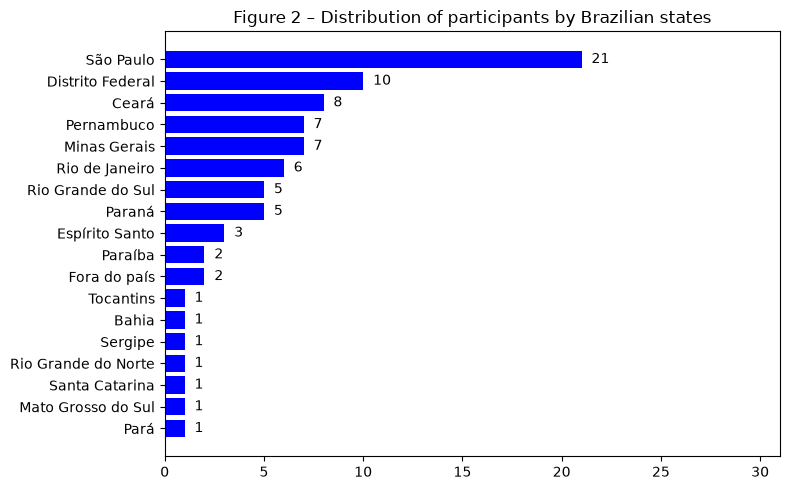

In [6]:
state_col = "Em qual estado do Brasil você mora atualmente?"  

# Count the number of participants per state
count_states = df[state_col].value_counts().sort_values(ascending=True)

# Create the horizontal bar chart
plt.figure(figsize=(8, 5))
plt.barh(count_states.index, count_states.values, color='blue')

# Add value labels
for i, v in enumerate(count_states.values):
    plt.text(v + 0.5, i, str(v), va='center')

# Titles and labels
plt.title("Figure 2 – Distribution of participants by Brazilian states", fontsize=12)
plt.xlabel("")
plt.ylabel("")
plt.xlim(0, count_states.values.max() + 10)
plt.tight_layout()
plt.show()


In [7]:
target_columns = {
    "Gender": "Qual é o seu gênero?",
    "Age group": "Qual é a sua idade?",
    "Academic background": "Qual é o seu nível de educação formal concluída?"
}

# Function to generate the summary
def summarize_column(df, column):
    total = df[column].notna().sum()  # total valid responses
    counts = df[column].value_counts().sort_values(ascending=False)
    percentage = (counts / total) * 100
    summary = pd.DataFrame({
        "Quantity": counts,
        "Percentage (%)": percentage.round(1)
    })
    return summary

# Generate the summary tables
for display_name, column_name in target_columns.items():
    print(f"\n===== {display_name.upper()} =====")
    if column_name in df.columns:
        print(summarize_column(df, column_name))
    else:
        print(f"❌ Column '{column_name}' not found. Check the exact name in the file.")



===== GENDER =====
                       Quantity  Percentage (%)
Qual é o seu gênero?                           
Homem                        70            84.3
Mulher                       12            14.5
Prefiro não responder         1             1.2

===== AGE GROUP =====
                     Quantity  Percentage (%)
Qual é a sua idade?                          
25 - 34 anos               44            53.0
18 - 24 anos               22            26.5
35 - 44 anos               14            16.9
45 - 54 anos                2             2.4
55 - 64 anos                1             1.2

===== ACADEMIC BACKGROUND =====
                                                  Quantity  Percentage (%)
Qual é o seu nível de educação formal concluída?                          
Ensino Superior                                         31            37.3
Ensino Médio                                            19            22.9
Especialização                                          18    

In [8]:
target_columns = {
    "Work model": "Qual seu modelo de trabalho?",
    "Seniority": "Por favor, indique a senioridade da posição que ocupa."
}

# Function to generate the summary
def summarize_column(df, column):
    total = df[column].notna().sum()  # total valid responses
    counts = df[column].value_counts().sort_values(ascending=False)
    percentage = (counts / total) * 100
    summary = pd.DataFrame({
        "Quantity": counts,
        "Percentage (%)": percentage.round(1)
    })
    return summary

# Generate the summary tables
for display_name, column_name in target_columns.items():
    print(f"\n===== {display_name.upper()} =====")
    if column_name in df.columns:
        print(summarize_column(df, column_name))
    else:
        print(f"❌ Column '{column_name}' not found. Check the exact name in the file.")



===== WORK MODEL =====
                              Quantity  Percentage (%)
Qual seu modelo de trabalho?                          
Remoto                              52            62.7
Híbrido                             26            31.3
Presencial                           5             6.0

===== SENIORITY =====
                                                    Quantity  Percentage (%)
Por favor, indique a senioridade da posição que...                          
Sênior (10+ anos)                                         34            41.0
Júnior (até 5 anos)                                       24            28.9
Pleno (6 a 9 anos)                                        16            19.3
Estagiário                                                 9            10.8


In [9]:
role_column = "Qual papel que melhor descreve suas atividades atuais em projetos de desenvolvimento de software?"

df = df.dropna(subset=[role_column])

total_participants = len(df)

def protect_parentheses(text):
    return re.sub(r"\(([^)]*)\)", lambda m: "(" + m.group(1).replace(",", "|") + ")", text)

corrected = df[role_column].apply(protect_parentheses)

all_answers = corrected.str.split(",").explode().str.strip()
all_answers = all_answers.str.replace("|", ",", regex=False)

counts = all_answers.value_counts().reset_index()
counts.columns = ["Role", "Quantity"]

counts["Percentage"] = (counts["Quantity"] / total_participants * 100).round(2)

print(f"\n=== Role Distribution (based on {total_participants} participants) ===\n")
print(counts)

results_path = Path('results/characterization')
counts.to_excel(results_path / "roles_analysis.xlsx", index=False)
print("\n'roles_analysis.xlsx' saved!")



=== Role Distribution (based on 83 participants) ===

                                        Role  Quantity  Percentage
0                          Security engineer        40       48.19
1                            DevOps engineer        27       32.53
2                         Penetration tester        26       31.33
3   Developer (Backend, frontend, fullstack)        12       14.46
4                         Solution Architect         8        9.64
5             Project Lead / Project Manager         6        7.23
6                             Data Scientist         4        4.82
7                           Privacy engineer         2        2.41
8                      Requirements Engineer         1        1.20
9                      Test Manager / Tester         1        1.20
10                                       SOC         1        1.20
11        Gerente de Segurança da Informação         1        1.20
12                        Application secure         1        1.20
13     

In [10]:
target_columns = {
    "ExpDS": "Quantos anos de experiência você tem em funções relacionadas ao desenvolvimento de software ou TI?",
    "ExpSS": "Quantos anos de experiência você tem em funções relacionadas a Segurança de Software?"
}

# Function to generate the summary
def summarize_column(df, column):
    total = df[column].notna().sum()  # total valid responses
    counts = df[column].value_counts().sort_values(ascending=False)
    percentage = (counts / total) * 100
    summary = pd.DataFrame({
        "Quantity": counts,
        "Percentage (%)": percentage.round(1)
    })
    return summary

# Generate the summary tables
for display_name, column_name in target_columns.items():
    print(f"\n===== {display_name.upper()} =====")
    if column_name in df.columns:
        print(summarize_column(df, column_name))
    else:
        print(f"❌ Column '{column_name}' not found. Check the exact name in the file.")



===== EXPDS =====
                                                    Quantity  Percentage (%)
Quantos anos de experiência você tem em funções...                          
Entre 7 e 14 anos                                         32            38.6
Entre 1 e 3 anos                                          24            28.9
Entre 4 e 5 anos                                          16            19.3
Mais de 15 anos                                            8             9.6
Menos de 1 ano                                             3             3.6

===== EXPSS =====
                                                    Quantity  Percentage (%)
Quantos anos de experiência você tem em funções...                          
Entre 1 e 3 anos                                          25            30.1
Entre 4 e 6 anos                                          24            28.9
Entre 7 e 14 anos                                         17            20.5
Menos de 1 ano                        

In [11]:
role_column = "Quais são os tipos de sistemas que você trabalha?"

df = df.dropna(subset=[role_column])

total_participants = len(df)

def protect_parentheses(text):
    return re.sub(r"\(([^)]*)\)", lambda m: "(" + m.group(1).replace(",", "|") + ")", text)

corrected = df[role_column].apply(protect_parentheses)

all_answers = corrected.str.split(",").explode().str.strip()
all_answers = all_answers.str.replace("|", ",", regex=False)

counts = all_answers.value_counts().reset_index()
counts.columns = ["System type", "Quantity"]

counts["Percentage"] = (counts["Quantity"] / total_participants * 100).round(2)

print(f"\n=== System Type Distribution (based on {total_participants} participants) ===\n")
print(counts)

results_path = Path('results/characterization')
counts.to_excel(results_path / "system_types_analysis.xlsx", index=False)
print("\n'system_types_analysis.xlsx' saved!")



=== System Type Distribution (based on 83 participants) ===

                                          System type  Quantity  Percentage
0                   Aplicações web (Web applications)        74       89.16
1             Aplicações móveis (Mobile applications)        42       50.60
2           Sistemas Operacionais (Operating Systems)        33       39.76
3           Aplicações desktop (Desktop applications)        32       38.55
4   Ferramentas para desenvolvedores (Developer to...        29       34.94
5       Aplicações embarcadas (Embedded applications)        16       19.28
6                             Middleware (Middleware)        15       18.07
7                        Não atuo com desenvolvimento         1        1.20
8                                               Todas         1        1.20
9                                                 API         1        1.20
10                              Ferramentas de AppSec         1        1.20
11                    Infr

In [12]:
role_column = "Quais são os domínios dos sistemas que você trabalha atualmente?"
df = df.dropna(subset=[role_column])

total_participants = len(df)

def protect_parentheses(text):
    return re.sub(r"\(([^)]*)\)", lambda m: "(" + m.group(1).replace(",", "|") + ")", text)

corrected = df[role_column].apply(protect_parentheses)

all_answers = corrected.str.split(",").explode().str.strip()
all_answers = all_answers.str.replace("|", ",", regex=False)

counts = all_answers.value_counts().reset_index()
counts.columns = ["System domain", "Quantity"]

counts["Percentage"] = (counts["Quantity"] / total_participants * 100).round(2)

print(f"\n=== System Domain Distribution (based on {total_participants} participants) ===\n")
print(counts)

results_path = Path('results/characterization')
counts.to_excel(results_path / "system_domains_analysis.xlsx", index=False)
print("\n'system_domains_analysis.xlsx' saved!")



=== System Domain Distribution (based on 83 participants) ===

                                        System domain  Quantity  Percentage
0               Bancos/Financeiro (Banking/Financial)        37       44.58
1             Defesa & Segurança (Defense & Security)        35       42.17
2                Vendas/E-commerce (Sales/E-commerce)        28       33.73
3                Telecomunicações (Telecommunication)        14       16.87
4                                Educação (Education)        13       15.66
5                                  Saúde (Healthcare)        12       14.46
6                                 Seguros (Insurance)         6        7.23
7                               Logística (Logistics)         6        7.23
8                      Entretenimento (Entertainment)         5        6.02
9   Sistemas embarcados em Automotivo ou Aviônica ...         2        2.41
10                    Sistemas de Tecnologia em Geral         1        1.20
11                      

In [13]:
role_column = "Qual é o setor da organização para qual você trabalha atualmente?"
df = df.dropna(subset=[role_column])

total_participants = len(df)

def protect_parentheses(text):
    return re.sub(r"\(([^)]*)\)", lambda m: "(" + m.group(1).replace(",", "|") + ")", text)

corrected = df[role_column].apply(protect_parentheses)

all_answers = corrected.str.split(",").explode().str.strip()
all_answers = all_answers.str.replace("|", ",", regex=False)

counts = all_answers.value_counts().reset_index()
counts.columns = ["Organization sector", "Quantity"]

counts["Percentage"] = (counts["Quantity"] / total_participants * 100).round(2)

print(f"\n=== Organization Sector Distribution (based on {total_participants} participants) ===\n")
print(counts)

results_path = Path('results/characterization')
counts.to_excel(results_path / "organization_sectors_analysis.xlsx", index=False)
print("\n'organization_sectors_analysis.xlsx' saved!")



=== Organization Sector Distribution (based on 83 participants) ===

                      Organization sector  Quantity  Percentage
0                           Setor privado        70       84.34
1                           Setor público        11       13.25
2                                 Startup         5        6.02
3  Projetos de pesquisa e desenvolvimento         3        3.61
4                                Autônomo         3        3.61
5         Organização sem fins lucrativos         1        1.20
6                                 Aviação         1        1.20

'organization_sectors_analysis.xlsx' saved!


In [14]:
target_columns = {
    "CompanySize": "Qual o tamanho da empresa para a qual você trabalha atualmente?",  
}

# Function to generate the summary
def summarize_column(df, column):
    total = df[column].notna().sum()  # total valid responses
    counts = df[column].value_counts().sort_values(ascending=False)
    percentage = (counts / total) * 100
    summary = pd.DataFrame({
        "Quantity": counts,
        "Percentage (%)": percentage.round(1)
    })
    return summary

# Generate the summary tables
for display_name, column_name in target_columns.items():
    print(f"\n===== {display_name.upper()} =====")
    if column_name in df.columns:
        print(summarize_column(df, column_name))
    else:
        print(f"❌ Column '{column_name}' not found. Check the exact name in the file.")



===== COMPANYSIZE =====
                                                    Quantity  Percentage (%)
Qual o tamanho da empresa para a qual você trab...                          
Mais de 1000 funcionários                                 43            51.8
De 100 a 499 funcionários                                 14            16.9
De 50 a 99 funcionários                                    9            10.8
De 500 a 999 funcionários                                  8             9.6
De 10 a 49 funcionários                                    6             7.2
Não sei                                                    2             2.4
Até 9 funcionários                                         1             1.2


In [15]:
target_columns = {
    "ExpSS": "Você tem (ou teve) alguma experiência de trabalho relacionada à segurança de software no processo de desenvolvimento de software?",
}

# Function to generate the summary
def summarize_column(df, column):
    total = df[column].notna().sum()  # total valid responses
    counts = df[column].value_counts().sort_values(ascending=False)
    percentage = (counts / total) * 100
    summary = pd.DataFrame({
        "Quantity": counts,
        "Percentage (%)": percentage.round(1)
    })
    return summary

# Generate the summary tables
for display_name, column_name in target_columns.items():
    print(f"\n===== {display_name.upper()} =====")
    if column_name in df.columns:
        print(summarize_column(df, column_name))
    else:
        print(f"❌ Column '{column_name}' not found. Check the exact name in the file.")



===== EXPSS =====
                                                    Quantity  Percentage (%)
Você tem (ou teve) alguma experiência de trabal...                          
Eu já trabalhei (ou trabalho) com segurança no ...        62            74.7
Meu grupo/equipe de desenvolvimento trabalha (o...        21            25.3


In [16]:
role_column = "Você possui alguma certificação na área de segurança da informação? Se sim, quais são elas?"

df = df.dropna(subset=[role_column])

total_participants = len(df)

def protect_parentheses(text):
    # Replaces commas inside parentheses with a temporary character
    return re.sub(r"\(([^)]*)\)", lambda m: "(" + m.group(1).replace(",", "|") + ")", text)

corrected = df[role_column].apply(protect_parentheses)

all_answers = corrected.str.split(",").explode().str.strip()
all_answers = all_answers.str.replace("|", ",", regex=False)

counts = all_answers.value_counts().reset_index()
counts.columns = ["Certification", "Quantity"]

counts["Percentage"] = (counts["Quantity"] / total_participants * 100).round(2)

print(f"\n=== Certification Distribution (based on {total_participants} participants) ===\n")
print(counts)

results_path = Path('results/characterization')
counts.to_excel(results_path / "certifications_analysis.xlsx", index=False)
print("\n'certifications_analysis.xlsx' saved!")



=== Certification Distribution (based on 83 participants) ===

                                        Certification  Quantity  Percentage
0                     Não possui nenhuma certificação        48       57.83
1                                   CompTIA Security+        11       13.25
2                      Certified Ethical Hacker (CEH)         8        9.64
3                                                DCPT         3        3.61
4                                           ISO 27001         3        3.61
5   Certified Information Systems Security Profess...         3        3.61
6    Offensive Security Certified Professional (OSCP)         3        3.61
7                                               eWPTX         2        2.41
8                                                CASE         2        2.41
9       Certified Information Security Manager (CISM)         2        2.41
10                                             SC-900         2        2.41
11  Certified Informatio